# TP4 · Fêtes et consommation au Sénégal : dix ans d'achats à la loupe

**ISM École d'ingénieurs · Python avancé · L3 IA **
**Auteur :** Papa Arona SENE ·

Notebook organisé en 7 parties (audit, variables d'événement, uplifts, prévision, endettement, segmentation, plan 2026), chacune terminée par une conclusion.
Découpage temporel : entraînement 2016-2023, validation 2024, test 2025 . 

## Partie 1 · Audit et nettoyage

On charge les ventes avec `parse_dates`, puis on cherche chaque défaut **avant** de corriger quoi que ce soit.

In [4]:
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
DATA_DIR = Path("data")
raw = pd.read_csv(DATA_DIR / "ventes_journalieres.csv", parse_dates=["date"])
categories = pd.read_csv(DATA_DIR / "categories.csv")
magasins = pd.read_csv(DATA_DIR / "magasins.csv", parse_dates=["date_ouverture"])
CATS = categories.categorie.tolist()

print(raw.shape)
raw.info()
raw.head()

(530790, 8)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 530790 entries, 0 to 530789
Data columns (total 8 columns):
 #   Column                 Non-Null Count   Dtype         
---  ------                 --------------   -----         
 0   date                   530790 non-null  datetime64[ns]
 1   magasin_id             530790 non-null  object        
 2   categorie              530790 non-null  object        
 3   quantite               529730 non-null  float64       
 4   prix_unitaire_fcfa     530790 non-null  float64       
 5   promo                  530790 non-null  int64         
 6   part_paiement_mobile   530790 non-null  float64       
 7   chiffre_affaires_fcfa  529730 non-null  float64       
dtypes: datetime64[ns](1), float64(4), int64(1), object(2)
memory usage: 32.4+ MB


,date,magasin_id,categorie,quantite,prix_unitaire_fcfa,promo,part_paiement_mobile,chiffre_affaires_fcfa
0,2016-01-01,M01,arachide_bouye,31.0,1175.0,0,0.034,36425.0
1,2016-01-01,M01,beaute_coiffure,46.0,2500.0,0,0.018,115000.0
2,2016-01-01,M01,betail_mouton,0.0,89500.0,0,0.000,0.0
3,2016-01-01,M01,boissons,265.0,500.0,0,0.000,132500.0
4,2016-01-01,M01,cereales_mil,56.0,375.0,0,0.008,21000.0


In [5]:
# 1) Doublons et catégories mal saisies
v = raw.copy()
v["categorie_norm"] = v["categorie"].str.strip().str.lower()
n_cat_mal = int((v["categorie"] != v["categorie_norm"]).sum())
print("Modalités de 'categorie' avant normalisation :", raw.categorie.nunique(), "| après :", v.categorie_norm.nunique())
print("Lignes avec une catégorie mal saisie (casse ou espace) :", n_cat_mal)
print("Exemples :", sorted(raw.categorie.unique())[:6])

cle = ["date", "magasin_id", "categorie_norm"]
n_dup_exact = int(raw.duplicated().sum())
n_dup_cle = int(v.duplicated(cle).sum())
print("Doublons exacts :", n_dup_exact, "| doublons sur la clé (date, magasin, catégorie normalisée) :", n_dup_cle)

v = (v.drop_duplicates(cle).drop(columns="categorie").rename(columns={"categorie_norm": "categorie"})
       .sort_values(["magasin_id", "categorie", "date"]).reset_index(drop=True))
print("Lignes après dédoublonnage :", len(v))

Modalités de 'categorie' avant normalisation : 60 | après : 15
Lignes avec une catégorie mal saisie (casse ou espace) : 530
Exemples : ['ARACHIDE_BOUYE', 'Arachide_bouye', 'BEAUTE_COIFFURE', 'BETAIL_MOUTON', 'BOISSONS', 'Beaute_coiffure']
Doublons exacts : 300 | doublons sur la clé (date, magasin, catégorie normalisée) : 300
Lignes après dédoublonnage : 530490


In [6]:
# 2) Valeurs manquantes, quantités négatives, cohérence du chiffre d'affaires
print(v.isna().sum()[lambda s: s > 0])
n_nan = int(v.quantite.isna().sum())
n_neg = int((v.quantite < 0).sum())
ca_incoh = int(((v.quantite * v.prix_unitaire_fcfa - v.chiffre_affaires_fcfa).abs() > 1).sum())
print("Quantités manquantes :", n_nan, "| négatives :", n_neg, "| CA incohérent avec quantité × prix :", ca_incoh)
print("NaN par année :", v[v.quantite.isna()].date.dt.year.value_counts().sort_index().to_dict())

quantite                 1060
chiffre_affaires_fcfa    1060
dtype: int64
Quantités manquantes : 1060 | négatives : 29 | CA incohérent avec quantité × prix : 0
NaN par année : {2016: 89, 2017: 83, 2018: 117, 2019: 89, 2020: 114, 2021: 111, 2022: 126, 2023: 124, 2024: 93, 2025: 114}


In [7]:
# 3) Valeurs aberrantes : on compare chaque vente à la médiane glissante (29 jours) du même point de vente et de la même catégorie.
# Un pic avant une fête reste modéré (rapport de l'ordre de 2 à 10) ; une erreur de saisie est sans commune mesure.
v["med_loc"] = v.groupby(["magasin_id", "categorie"]).quantite.transform(lambda s: s.rolling(29, center=True, min_periods=10).median())
v["rapport_loc"] = v.quantite / v.med_loc
x = v[v.categorie != "betail_mouton"]
bins = pd.cut(x.rapport_loc, [-np.inf, 0, 5, 10, 20, 50, np.inf], labels=["≤0", "0-5", "5-10", "10-20", "20-50", ">50"])
print(bins.value_counts().sort_index())
print("Plus forts rapports :", x.rapport_loc.nlargest(5).round(0).tolist())
SEUIL_ABERRANT = 20
masque_aberrant = (v.rapport_loc > SEUIL_ABERRANT) & (v.categorie != "betail_mouton")
n_aberr = int(masque_aberrant.sum())
print("Valeurs aberrantes (rapport >", SEUIL_ABERRANT, ") :", n_aberr)
v[masque_aberrant].sort_values("rapport_loc", ascending=False).head(6)[["date", "magasin_id", "categorie", "quantite", "med_loc", "rapport_loc"]]

rapport_loc
≤0          174
0-5      493804
5-10        107
10-20         0
20-50         0
>50          36
Name: count, dtype: int64
Plus forts rapports : [180.0, 154.0, 138.0, 130.0, 127.0]
Valeurs aberrantes (rapport > 20 ) : 36


,date,magasin_id,categorie,quantite,med_loc,rapport_loc
519230,2018-09-09,M10,riz,42900.0,238.0,180.252101
376033,2020-09-27,M07,volaille,3700.0,24.0,154.166667
55691,2018-06-15,M02,arachide_bouye,3600.0,26.0,138.461538
430834,2020-10-03,M08,volaille,3000.0,23.0,130.434783
178415,2024-09-26,M04,boissons,25200.0,199.0,126.633166
207158,2023-06-03,M04,riz,51000.0,409.0,124.694377


In [8]:
# Les ratios de 5 à 10 sont-ils bien des pics de fête ? (vérification après la partie 2, voir plus bas)
# 4) Jours manquants par point de vente (par rapport à la date d'ouverture)
FIN = pd.Timestamp("2025-12-31")
lignes = []
for _, m in magasins.iterrows():
    debut = max(m.date_ouverture, pd.Timestamp("2016-01-01"))
    attendus = pd.date_range(debut, FIN)
    presents = v.loc[v.magasin_id == m.magasin_id, "date"].unique()
    manquants = attendus.difference(presents)
    lignes.append({"magasin_id": m.magasin_id, "ville": m.ville, "ouverture": m.date_ouverture.date(), "jours_attendus": len(attendus),
                   "jours_manquants": len(manquants), "premier": manquants.min().date() if len(manquants) else None,
                   "dernier": manquants.max().date() if len(manquants) else None})
jours_manquants = pd.DataFrame(lignes)
n_jours_manq = int(jours_manquants.jours_manquants.sum())
jours_manquants

,magasin_id,ville,ouverture,jours_attendus,jours_manquants,premier,dernier
0,M01,Dakar Plateau,2016-01-01,3653,0,None,None
1,M02,Parcelles Assainies,2016-01-01,3653,0,None,None
2,M03,Pikine,2016-01-01,3653,8,2021-03-05,2021-03-12
3,M04,Thiès,2016-01-01,3653,0,None,None
4,M05,Touba,2016-01-01,3653,0,None,None
5,M06,Tivaouane,2017-01-01,3287,0,None,None
6,M07,Kaolack,2016-01-01,3653,0,None,None
7,M08,Saint-Louis,2016-01-01,3653,0,None,None
8,M09,Ziguinchor,2016-01-01,3653,0,None,None
9,M10,Mbour,2018-03-01,2863,0,None,None


In [9]:
# 5) Traitement
v["imputee"] = v.quantite.isna() | (v.quantite < 0) | masque_aberrant          # lignes dont la quantité n'est pas fiable
v.loc[(v.quantite < 0) | masque_aberrant, "quantite"] = np.nan
loc7 = v.groupby(["magasin_id", "categorie"]).quantite.transform(lambda s: s.rolling(7, center=True, min_periods=3).median())
v["quantite"] = v.quantite.fillna(loc7).fillna(v.med_loc).round()
v["chiffre_affaires_fcfa"] = v.quantite * v.prix_unitaire_fcfa                   # recalculé : la quantité était fausse ou absente
clean = v[["date", "magasin_id", "categorie", "quantite", "prix_unitaire_fcfa", "promo", "part_paiement_mobile", "chiffre_affaires_fcfa", "imputee"]].reset_index(drop=True)
print("Lignes nettoyées :", len(clean), "| lignes imputées (exclues des métriques) :", int(clean.imputee.sum()))
print("Reste-t-il des NaN ou des négatifs ?", int(clean.quantite.isna().sum()), int((clean.quantite < 0).sum()))

rapport_audit = pd.DataFrame([
    ["Doublons (clé date × magasin × catégorie)", n_dup_cle, "Supprimés (on garde la première occurrence) : une vente ne se compte qu'une fois."],
    ["Catégories mal saisies (casse, espaces)", n_cat_mal, "Normalisées par strip().lower() : 60 écritures pour 15 catégories réelles."],
    ["Quantités manquantes", n_nan, "Imputées par la médiane glissante de 7 jours du même magasin et de la même catégorie, puis exclues des métriques."],
    ["Quantités négatives", n_neg, "Mises à NaN puis imputées comme ci-dessus : une vente ne peut pas être négative (erreur de signe ou retour non documenté)."],
    ["Valeurs aberrantes (> 20 × médiane locale)", n_aberr, "Mises à NaN puis imputées ; les pics de fête (rapport < 10) sont conservés car ils sont réels."],
    ["Chiffre d'affaires incohérent", ca_incoh, "Aucun défaut sur les lignes brutes ; le CA est recalculé (quantité × prix) pour les lignes imputées."],
    ["Jours manquants (point de vente M03)", n_jours_manq, "Laissés absents : on n'invente pas des ventes un jour de fermeture probable ; l'effet est négligeable (8 jours sur 3 653)."],
], columns=["Défaut", "Nombre", "Traitement"])
rapport_audit

Lignes nettoyées : 530490 | lignes imputées (exclues des métriques) : 1125
Reste-t-il des NaN ou des négatifs ? 0 0


,Défaut,Nombre,Traitement
0,Doublons (clé date × magasin × catégorie),300,Supprimés (on garde la première occurrence) : ...
1,"Catégories mal saisies (casse, espaces)",530,Normalisées par strip().lower() : 60 écritures...
2,Quantités manquantes,1060,Imputées par la médiane glissante de 7 jours d...
3,Quantités négatives,29,Mises à NaN puis imputées comme ci-dessus : un...
4,Valeurs aberrantes (> 20 × médiane locale),36,Mises à NaN puis imputées ; les pics de fête (...
5,Chiffre d'affaires incohérent,0,Aucun défaut sur les lignes brutes ; le CA est...
6,Jours manquants (point de vente M03),8,Laissés absents : on n'invente pas des ventes ...


### Conclusion de la partie 1
Le fichier contient sept familles de défauts : **300 doublons**, **530 lignes à catégorie mal saisie** (60 écritures pour 15 catégories), **1 060 quantités manquantes**, **29 négatives**, **36 valeurs aberrantes** et **8 jours manquants** à Pikine (M03, du 5 au 12 mars 2021). Le chiffre d'affaires est cohérent avec quantité × prix partout.

La frontière entre erreur et pic de fête est nette : aucun rapport à la médiane locale entre 10 et 50, les 36 erreurs dépassent 50 (jusqu'à 180) alors que les 107 pics réels restent entre 5 et 10 et tombent tous dans les 14 jours avant une fête (vérification faite après la partie 2). On garde donc les pics, on impute 1 125 lignes (médiane glissante de 7 jours), qu'on exclut de l'entraînement et des métriques, et on obtient 530 490 lignes propres.

## Partie 2 · Variables d'événement avec `merge_asof`

Pour chaque date et chaque fête : `av_<fête>` = jours avant la **prochaine** occurrence, `ap_<fête>` = jours depuis la **précédente**, plafonnés (60 et 30 jours), plus un indicateur `ramadan`. Aucune boucle sur les lignes de ventes : on calcule sur les **dates uniques** (3 653 lignes), puis on fusionne.

In [10]:
cal = pd.read_csv(DATA_DIR / "calendrier_evenements.csv", parse_dates=["date_debut", "date_fin"])
FETES = {"korite": "Korité", "tabaski": "Tabaski", "tamkharit": "Tamkharit", "magal": "Magal de Touba",
         "maouloud": "Maouloud", "paques": "Pâques", "popenguine": "Pèlerinage de Popenguine", "noel": "Noël"}
CAP_AV, CAP_AP = 60, 30

def variables_calendrier(dates, cap_av=CAP_AV, cap_ap=CAP_AP):
    # Pour chaque date unique : av_<fête>, ap_<fête> (jours, plafonnés) et ramadan (0/1)
    d = pd.DataFrame({"date": pd.Series(pd.to_datetime(dates)).drop_duplicates().sort_values().values})
    out = d.copy()
    for cle_f, nom in FETES.items():
        ev = cal.loc[cal.evenement == nom, ["date_debut"]].rename(columns={"date_debut": "date_fete"}).sort_values("date_fete")
        suivante = pd.merge_asof(d, ev, left_on="date", right_on="date_fete", direction="forward")
        precedente = pd.merge_asof(d, ev, left_on="date", right_on="date_fete", direction="backward", allow_exact_matches=False)
        out["av_" + cle_f] = (suivante["date_fete"] - d["date"]).dt.days.fillna(cap_av).clip(upper=cap_av).astype(int)
        out["ap_" + cle_f] = (d["date"] - precedente["date_fete"]).dt.days.fillna(cap_ap).clip(upper=cap_ap).astype(int)
    ram = cal.loc[cal.evenement == "Ramadan", ["date_debut", "date_fin"]].sort_values("date_debut")
    r = pd.merge_asof(d, ram, left_on="date", right_on="date_debut", direction="backward")
    out["ramadan"] = (d["date"] <= r["date_fin"]).astype(int)
    return out

cf = variables_calendrier(clean.date)
print(cf.shape)
cf[cf.date.between("2025-05-28", "2025-06-10")][["date", "av_tabaski", "ap_tabaski", "av_popenguine", "ap_popenguine", "ramadan"]]

(3653, 18)


,date,av_tabaski,ap_tabaski,av_popenguine,ap_popenguine,ramadan
3435,2025-05-28,10,30,12,30,0
3436,2025-05-29,9,30,11,30,0
3437,2025-05-30,8,30,10,30,0
3438,2025-05-31,7,30,9,30,0
3439,2025-06-01,6,30,8,30,0
3440,2025-06-02,5,30,7,30,0
3441,2025-06-03,4,30,6,30,0
3442,2025-06-04,3,30,5,30,0
3443,2025-06-05,2,30,4,30,0
3444,2025-06-06,1,30,3,30,0


Décalage moyen par an : -10.5 jours | min -11.0 | max -10.0


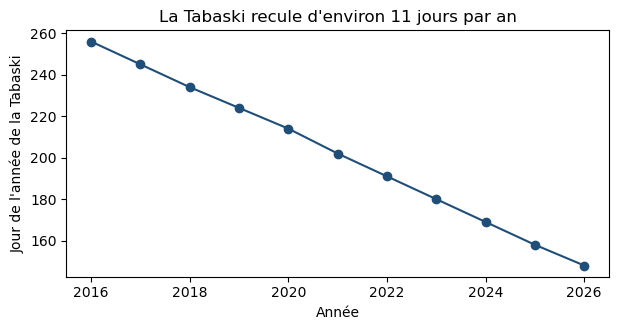

,annee,date_debut,jour_de_l_annee,mois,decalage_jours
0,2016,2016-09-12,256,September,NaN
1,2017,2017-09-02,245,September,-10.0
2,2018,2018-08-22,234,August,-11.0
3,2019,2019-08-12,224,August,-10.0
4,2020,2020-08-01,214,August,-10.0
5,2021,2021-07-21,202,July,-11.0
6,2022,2022-07-10,191,July,-11.0
7,2023,2023-06-29,180,June,-11.0
8,2024,2024-06-17,169,June,-11.0
9,2025,2025-06-07,158,June,-10.0


In [11]:
# Décalage de la Tabaski d'une année sur l'autre
tab = cal[cal.evenement == "Tabaski"][["annee", "date_debut"]].reset_index(drop=True)
tab["jour_de_l_annee"] = tab.date_debut.dt.dayofyear
tab["mois"] = tab.date_debut.dt.month_name()
tab["decalage_jours"] = tab.date_debut.diff().dt.days - 365   # écart par rapport à la même date de l'année précédente (ignore les bissextiles)
print("Décalage moyen par an :", tab.decalage_jours.mean().round(1), "jours | min", tab.decalage_jours.min(), "| max", tab.decalage_jours.max())
fig, ax = plt.subplots(figsize=(7, 3.2))
ax.plot(tab.annee, tab.jour_de_l_annee, "o-", color="#1f4e79")
ax.set_xlabel("Année"); ax.set_ylabel("Jour de l'année de la Tabaski"); ax.set_title("La Tabaski recule d'environ 11 jours par an")
plt.show()
tab

In [12]:
# Pourquoi la variable « mois » ne suffit pas : l'effet de la Tabaski se retrouve dans des mois différents selon l'année
mois_pic = (clean[clean.categorie == "betail_mouton"].groupby([clean.date.dt.year.rename("annee"), clean.date.dt.month.rename("mois")]).quantite.sum()
            .reset_index().sort_values("quantite", ascending=False).groupby("annee").head(1).sort_values("annee"))
print("Mois du pic annuel de ventes de moutons :")
print(mois_pic.set_index("annee").mois.to_dict())

Mois du pic annuel de ventes de moutons :
{2016: 9, 2017: 8, 2018: 8, 2019: 8, 2020: 7, 2021: 7, 2022: 7, 2023: 6, 2024: 6, 2025: 6}


In [13]:
# Vérification de la partie 1 : les rapports de 5 à 10 sont-ils bien des pics de fête (donc à conserver) ?
AV = ["av_" + k for k in FETES]
pics = v[(v.categorie != "betail_mouton") & (v.rapport_loc > 5) & (v.rapport_loc <= SEUIL_ABERRANT)].merge(cf, on="date", how="left")
dans_fenetre = (pics[AV].ge(0) & pics[AV].le(14)).any(axis=1)
print("Ventes avec rapport entre 5 et 20 :", len(pics), "| dont dans les 14 jours avant une fête :", int(dans_fenetre.sum()))

Ventes avec rapport entre 5 et 20 : 107 | dont dans les 14 jours avant une fête : 107


### Conclusion de la partie 2
`variables_calendrier` produit `av_*`, `ap_*` (plafonnés à 60 et 30 jours) et `ramadan` en un seul passage par `merge_asof` sur les 3 653 dates uniques, sans boucle sur les 530 000 lignes de ventes.

La Tabaski recule de **10 à 11 jours par an** (10,5 en moyenne) : du 12 septembre 2016 au 7 juin 2025, puis le 28 mai 2026. Une variable « mois » est donc piégeante : le pic annuel des moutons passe de septembre (2016) à août, juillet puis juin (depuis 2023). Un modèle qui apprendrait « pic en septembre » sur 2016-2017 se tromperait de plusieurs mois en 2025. La distance en jours à la prochaine fête reste valable quelle que soit la dérive, et elle capte aussi l'effet de montée en puissance avant J0. Le raisonnement vaut pour toutes les fêtes lunaires (Korité, Tamkharit, Magal, Maouloud), alors que Noël est fixe et que Pâques oscille sur environ cinq semaines.

## Partie 3 · Mesurer l'effet des fêtes

**Fenêtre d'achat** (par fête, en jours avant J0) et **période de référence** J-60 à J-31. L'**uplift** = vente moyenne par jour dans la fenêtre ÷ vente moyenne par jour dans la référence. Fenêtres choisies d'après les profils observés (Tabaski J-7 à J-1 comme dans l'énoncé ; Ramadan = tout le mois, référence calculée avant son début).

In [14]:
WIN = {"Ramadan": None, "Korité": (-5, -1), "Pâques": (-3, -1), "Pèlerinage de Popenguine": (-3, -1), "Tabaski": (-7, -1),
       "Tamkharit": (-3, -1), "Magal de Touba": (-5, -1), "Maouloud": (-3, -1), "Noël": (-7, -1)}
REF = (-60, -31)
J = lambda n: pd.Timedelta(days=int(n))

def bornes(ligne, win=None):
    # fenêtre d'achat d'une occurrence (Ramadan : du début à la fin du jeûne)
    nom, d0 = ligne.evenement, ligne.date_debut
    if WIN[nom] is None:
        return d0, ligne.date_fin
    return d0 + J(WIN[nom][0]), d0 + J(WIN[nom][1])

def uplifts(daily, nom, masque=None):
    # uplift de chaque occurrence de la fête `nom` ; daily : DataFrame indexé par date
    d = daily if masque is None else daily.mask(masque.reindex(daily.index, fill_value=False), np.nan)
    res = []
    for _, r in cal[cal.evenement == nom].iterrows():
        a, b = bornes(r)
        r0, r1 = r.date_debut + J(REF[0]), r.date_debut + J(REF[1])
        if r0 < d.index.min() or b > d.index.max():
            continue
        res.append((d.loc[a:b].mean() / d.loc[r0:r1].mean()).rename(r.annee))
    return pd.DataFrame(res)

qte_nat = clean.pivot_table(index="date", columns="categorie", values="quantite", aggfunc="sum")
up = {nom: uplifts(qte_nat, nom) for nom in WIN}
U = pd.DataFrame({nom: t.median() for nom, t in up.items()}).T       # médiane des occurrences : événement × catégorie
print("Occurrences mesurées par fête :", {nom: len(t) for nom, t in up.items()})
top3 = {nom: U.loc[nom].nlargest(3).round(2).to_dict() for nom in U.index}
pd.DataFrame(top3, index=["1ère", "2e", "3e"]).T if False else pd.DataFrame({k: [f"{c} (×{x})" for c, x in d.items()] for k, d in top3.items()}, index=["1ère", "2e", "3e"]).T

Occurrences mesurées par fête : {'Ramadan': 10, 'Korité': 10, 'Pâques': 10, 'Pèlerinage de Popenguine': 10, 'Tabaski': 10, 'Tamkharit': 10, 'Magal de Touba': 10, 'Maouloud': 10, 'Noël': 10}


,1ère,2e,3e
Ramadan,dattes (×3.97),lait (×1.91),sucre (×1.81)
Korité,dattes (×4.14),tissus_habillement (×2.72),beaute_coiffure (×2.56)
Pâques,arachide_bouye (×2.82),volaille (×1.57),boissons (×1.5)
Pèlerinage de Popenguine,betail_mouton (×1.48),riz (×1.1),credit_mobile (×1.08)
Tabaski,betail_mouton (×10.64),oignons (×2.73),tissus_habillement (×2.4)
Tamkharit,cereales_mil (×2.56),volaille (×1.85),lait (×1.43)
Magal de Touba,credit_mobile (×1.51),boissons (×1.4),riz (×1.4)
Maouloud,sucre (×1.42),boissons (×1.4),riz (×1.29)
Noël,jouets_cadeaux (×3.98),volaille (×1.82),boissons (×1.63)


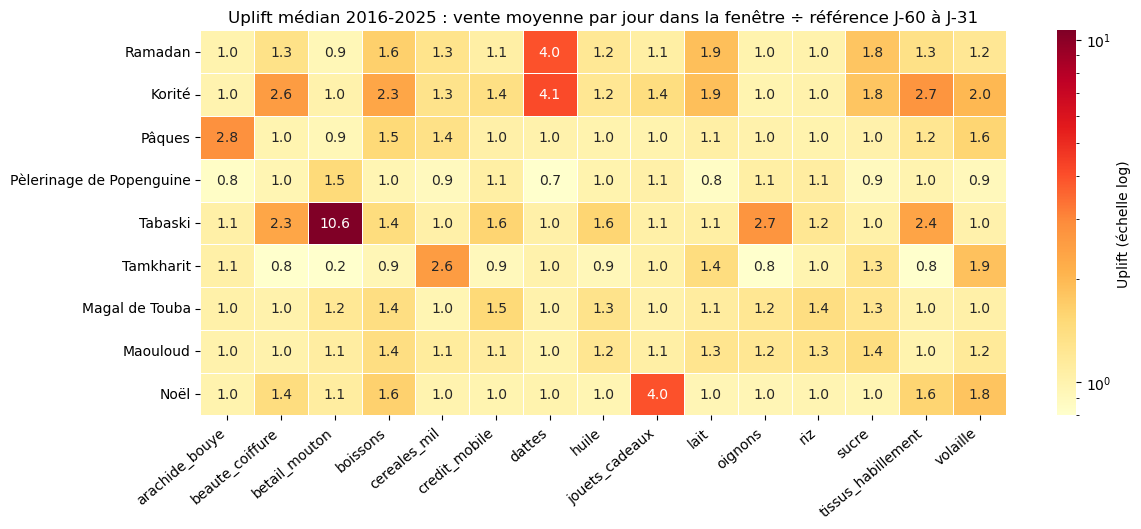

In [15]:
# Carte de chaleur événement × catégorie (échelle logarithmique)
from matplotlib.colors import LogNorm
fig, ax = plt.subplots(figsize=(13, 5))
sns.heatmap(U, annot=True, fmt=".1f", cmap="YlOrRd", norm=LogNorm(vmin=0.8, vmax=U.max().max()), linewidths=.4, cbar_kws={"label": "Uplift (échelle log)"}, ax=ax)
ax.set_title("Uplift médian 2016-2025 : vente moyenne par jour dans la fenêtre ÷ référence J-60 à J-31")
ax.set_xlabel(""); ax.set_ylabel(""); plt.xticks(rotation=40, ha="right")
plt.show()

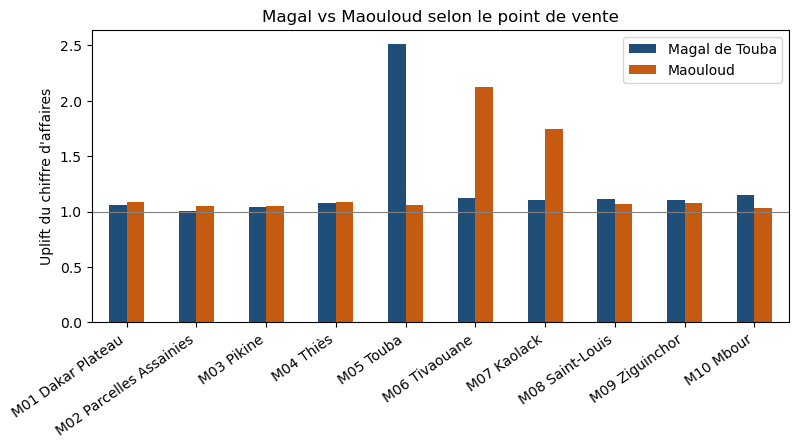

,Magal de Touba,Maouloud
M01 Dakar Plateau,1.055240,1.087034
M05 Touba,2.511542,1.061076
M06 Tivaouane,1.118698,2.120437
M07 Kaolack,1.104864,1.747322


In [16]:
# Magal et Maouloud par point de vente (uplift du chiffre d'affaires total du magasin)
ca_mag = clean.pivot_table(index="date", columns="magasin_id", values="chiffre_affaires_fcfa", aggfunc="sum")
ville = magasins.set_index("magasin_id").ville
compar = pd.DataFrame({n: uplifts(ca_mag, n).median() for n in ["Magal de Touba", "Maouloud"]})
compar.index = [f"{m} {ville[m]}" for m in compar.index]
fig, ax = plt.subplots(figsize=(9, 3.8))
compar.plot.bar(ax=ax, color=["#1f4e79", "#c55a11"]); ax.axhline(1, color="grey", lw=.8)
ax.set_ylabel("Uplift du chiffre d'affaires"); ax.set_title("Magal vs Maouloud selon le point de vente"); plt.xticks(rotation=35, ha="right"); plt.show()
compar.loc[[i for i in compar.index if i.split()[1] in ("Touba", "Tivaouane", "Kaolack", "Dakar")]]

In [17]:
# Chevauchements : on cherche les occurrences dont la fenêtre ou la référence contient des jours d'une AUTRE fête (J-7 à J0, ou Ramadan entier)
def fenetre_complete(r):
    a, b = bornes(r)
    return a, (r.date_debut if WIN[r.evenement] is not None else b)
tous = [(r.evenement, r.annee, *fenetre_complete(r)) for _, r in cal.iterrows()]
def jours_pollues(r, a, b):
    jours = set(pd.date_range(a, b))
    pol = {}
    for nom, an, x, y in tous:
        if nom == r.evenement and an == r.annee:
            continue
        inter = jours & set(pd.date_range(x, y))
        if inter:
            pol[f"{nom} {an}"] = len(inter)
    return pol
lignes = []
for _, r in cal.iterrows():
    if r.date_debut + J(REF[0]) < pd.Timestamp("2016-01-01") or r.date_debut > FIN:
        continue
    a, b = bornes(r)
    pw, pr = jours_pollues(r, a, b), jours_pollues(r, r.date_debut + J(REF[0]), r.date_debut + J(REF[1]))
    lignes.append({"fête": r.evenement, "année": r.annee, "j_fenetre_pollues": sum(pw.values()), "autres_dans_fenetre": ", ".join(pw),
                   "j_ref_pollues": sum(pr.values()), "autres_dans_ref": ", ".join(pr)})
chev = pd.DataFrame(lignes)
print("Occurrences dont la FENÊTRE chevauche une autre fête :", int((chev.j_fenetre_pollues > 0).sum()), "sur", len(chev))
print("Occurrences dont la RÉFÉRENCE chevauche une autre fête :", int((chev.j_ref_pollues > 0).sum()), "sur", len(chev))
chev[chev.j_fenetre_pollues > 0].sort_values("j_fenetre_pollues", ascending=False).head(12)

Occurrences dont la FENÊTRE chevauche une autre fête : 27 sur 90
Occurrences dont la RÉFÉRENCE chevauche une autre fête : 47 sur 90


,fête,année,j_fenetre_pollues,autres_dans_fenetre,j_ref_pollues,autres_dans_ref
10,Ramadan,2017,9,"Pèlerinage de Popenguine 2017, Korité 2017",4,Pâques 2017
19,Ramadan,2018,9,"Pèlerinage de Popenguine 2018, Korité 2018",4,Pâques 2018
72,Ramadan,2024,9,"Pâques 2024, Korité 2024",0,
63,Ramadan,2023,9,"Pâques 2023, Korité 2023",0,
54,Ramadan,2022,9,"Pâques 2022, Korité 2022",0,
2,Ramadan,2016,5,Korité 2016,0,
3,Korité,2016,5,Ramadan 2016,4,Pèlerinage de Popenguine 2016
82,Korité,2025,5,Ramadan 2025,0,
81,Ramadan,2025,5,Korité 2025,0,
74,Korité,2024,5,Ramadan 2024,0,


In [18]:
# Exemple retenu : Popenguine (lundi de Pentecôte) tombe 2 jours après la Tabaski en 2025.
# Son « uplift » sur les moutons mesure alors la Tabaski, pas le pèlerinage.
tab_dates = cal[cal.evenement == "Tabaski"].set_index("annee").date_debut
pop = cal[cal.evenement == "Pèlerinage de Popenguine"].set_index("annee").date_debut
exemple = pd.DataFrame({"jours entre Popenguine et Tabaski": (pop - tab_dates).dt.days,
                        "uplift moutons (brut)": up["Pèlerinage de Popenguine"]["betail_mouton"]}).dropna()
# Version corrigée : on retire des moyennes tous les jours appartenant à la fenêtre d'une AUTRE fête
mask_autres = pd.Series(False, index=qte_nat.index)
for nom, an, x, y in tous:
    if nom != "Pèlerinage de Popenguine":
        mask_autres.loc[x:y] = True
mask_df = pd.DataFrame(np.repeat(mask_autres.values[:, None], qte_nat.shape[1], axis=1), index=qte_nat.index, columns=qte_nat.columns)
exemple["uplift moutons (corrigé)"] = uplifts(qte_nat, "Pèlerinage de Popenguine", masque=mask_df)["betail_mouton"]
exemple

,jours entre Popenguine et Tabaski,uplift moutons (brut),uplift moutons (corrigé)
2016,-119,2.173913,2.280702
2017,-89,1.315789,NaN
2018,-93,1.200000,NaN
2019,-63,1.538462,1.571429
2020,-61,0.666667,0.666667
2021,-58,1.688312,1.650794
2022,-34,2.777778,5.000000
2023,-31,1.125000,2.250000
2024,-28,1.428571,1.386667
2025,2,7.611940,0.448276


C:\Users\admin\AppData\Local\Temp\ipykernel_30492\987377284.py:19: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  mobile = c.groupby("annee").apply(lambda g: (g.part_paiement_mobile * g.chiffre_affaires_fcfa).sum() / g.chiffre_affaires_fcfa.sum())


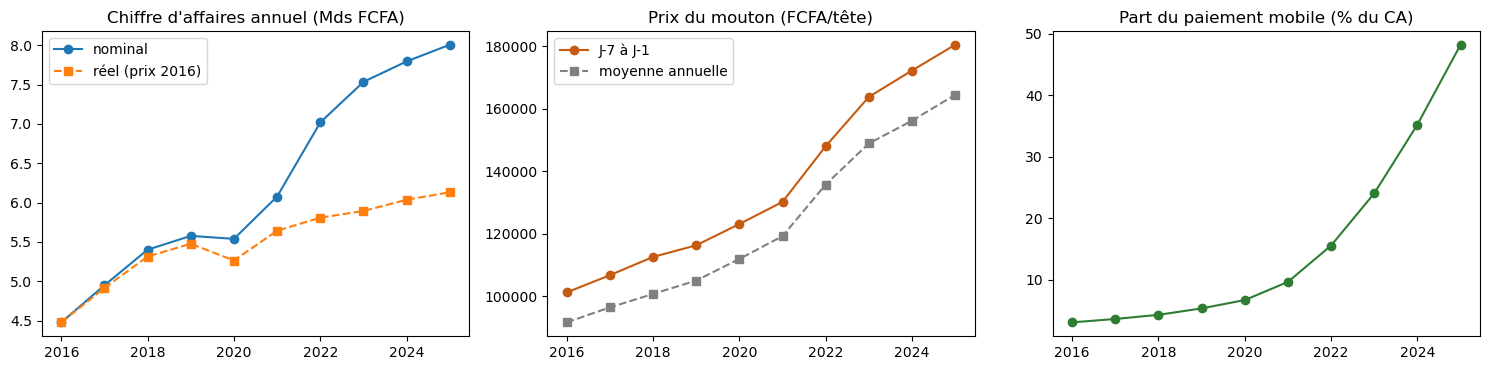

,CA nominal (Mds FCFA),indice des prix (2016=1),CA réel (Mds FCFA 2016),part paiement mobile (%)
annee,,,,
2016,4.477055,1.000000,4.477055,3.057350
2017,4.948637,1.006966,4.914403,3.614783
2018,5.401320,1.016349,5.314433,4.285376
2019,5.576758,1.018250,5.476807,5.332503
2020,5.539109,1.052364,5.263491,6.684517
2021,6.077377,1.077025,5.642745,9.638437
2022,7.019442,1.208514,5.808324,15.547090
2023,7.534808,1.278627,5.892891,24.036212
2024,7.794906,1.291324,6.036369,35.218286


,prix_avant_tabaski,prix_moyen_annuel,surprime_%
2016,101276.785714,91693.647541,10.451256
2017,106793.650794,96485.235921,10.683930
2018,112635.714286,100793.511557,11.748973
2019,116350.000000,105085.479452,10.719388
2020,123164.285714,111994.535519,9.973478
2021,130242.857143,119289.813289,9.181877
2022,148071.428571,135807.534247,9.030349
2023,163842.857143,148946.027397,10.001495
2024,172285.714286,156235.928962,10.272788
2025,180535.714286,164516.986301,9.736823


In [19]:
# Évolution sur dix ans : CA nominal/réel, prix du mouton avant la Tabaski, part du paiement mobile
c = clean.assign(annee=clean.date.dt.year)
ca_nominal = c.groupby("annee").chiffre_affaires_fcfa.sum()
# Indice des prix : somme sur c de poids2016(c) × prix médian(a, c) / prix médian(2016, c)
poids = c[c.annee == 2016].groupby("categorie").chiffre_affaires_fcfa.sum()
poids = poids / poids.sum()
prix_med = c.groupby(["annee", "categorie"]).prix_unitaire_fcfa.median().unstack()
indice = (prix_med / prix_med.loc[2016]).mul(poids, axis=1).sum(axis=1)
ca_reel = ca_nominal / indice
# Prix du mouton dans les 7 jours avant la Tabaski (moyenne tous magasins) vs prix annuel moyen
mouton = clean[clean.categorie == "betail_mouton"]
prix_pre = {}
for an, d0 in tab_dates.items():
    m = mouton[mouton.date.between(d0 - J(7), d0 - J(1))]
    if len(m): prix_pre[an] = m.prix_unitaire_fcfa.mean()
prix_an = mouton.groupby(mouton.date.dt.year).prix_unitaire_fcfa.mean()
prix_mouton = pd.DataFrame({"prix_avant_tabaski": pd.Series(prix_pre), "prix_moyen_annuel": prix_an}).dropna()
prix_mouton["surprime_%"] = 100 * (prix_mouton.prix_avant_tabaski / prix_mouton.prix_moyen_annuel - 1)
mobile = c.groupby("annee").apply(lambda g: (g.part_paiement_mobile * g.chiffre_affaires_fcfa).sum() / g.chiffre_affaires_fcfa.sum())
bilan = pd.DataFrame({"CA nominal (Mds FCFA)": ca_nominal / 1e9, "indice des prix (2016=1)": indice, "CA réel (Mds FCFA 2016)": ca_reel / 1e9, "part paiement mobile (%)": mobile * 100})

fig, ax = plt.subplots(1, 3, figsize=(15, 3.8))
ax[0].plot(bilan.index, bilan.iloc[:, 0], "o-", label="nominal"); ax[0].plot(bilan.index, bilan.iloc[:, 2], "s--", label="réel (prix 2016)")
ax[0].set_title("Chiffre d'affaires annuel (Mds FCFA)"); ax[0].legend()
ax[1].plot(prix_mouton.index, prix_mouton.prix_avant_tabaski, "o-", color="#c55a11", label="J-7 à J-1"); ax[1].plot(prix_mouton.index, prix_mouton.prix_moyen_annuel, "s--", color="grey", label="moyenne annuelle")
ax[1].set_title("Prix du mouton (FCFA/tête)"); ax[1].legend()
ax[2].plot(bilan.index, bilan.iloc[:, 3], "o-", color="#2e7d32"); ax[2].set_title("Part du paiement mobile (% du CA)")
plt.tight_layout(); plt.show()
display(bilan)
prix_mouton

### Conclusion de la partie 3
**Catégories les plus touchées** (uplift médian national) : Tabaski → moutons (×10,6), oignons (×2,7), tissus (×2,4) ; Noël → jouets (×4,0), volaille, boissons ; Korité → dattes (×4,1), tissus, beauté ; Pâques → arachide (×2,8) ; Tamkharit → céréales de mil (×2,6) ; Magal → recharges mobiles, boissons, riz (×1,4 à 1,5) ; Maouloud → sucre, boissons, riz.

**Magal et Maouloud sont des effets locaux.** Le Magal multiplie par **2,5** le chiffre d'affaires de Touba, mais Dakar (×1,06) et Kaolack (×1,1) n'en sentent presque rien. Le Maouloud fait ×2,1 à Tivaouane et ×1,7 à Kaolack, et ×1,09 à Dakar. Un modèle national moyenné gommerait ces deux pics : la prévision doit croiser point de vente et fête.

**Chevauchements.** 27 occurrences sur 90 ont une fenêtre qui touche une autre fête et 47 sur 90 une période de référence contaminée. Cas retenu : en 2025, le lundi de Pentecôte (Popenguine, 9 juin) tombe deux jours après la Tabaski. L'uplift « Popenguine » des moutons vaut **7,6** en brut, mais **0,45** une fois les jours des autres fêtes retirés (contre 0,7 à 2,8 les autres années) : c'est la Tabaski qu'on mesurait. De même, la fenêtre de la Korité se situe dans le Ramadan, si bien que son uplift (dattes ×4,1) reflète surtout le mois de jeûne (×4,0).

**Dix ans.** Le CA nominal passe de 4,5 à 8,0 milliards de FCFA (+79 %), mais en francs constants (indice des prix 1,31 en 2025) la hausse n'est que de **+37 %**. Le mouton coûte 10 % de plus dans la semaine avant la Tabaski que le reste de l'année, et son prix a bondi de 101 000 à 181 000 FCFA (+78 %), bien plus vite que l'indice général. La part du paiement mobile passe de 3 % à **48 %** du CA, avec une accélération nette après 2020.

## Partie 4 · Prévoir la demande un an à l'avance

**Cible** : quantité vendue par jour × point de vente × catégorie. **Métrique** : WAPE = Σ|réel − prévu| ÷ Σ réel, sur l'année entière et sur les **fenêtres d'événement** (J-14 à J-1 avant une des 8 fêtes).
**Variables autorisées** (connues un an à l'avance) : calendrier (`av_*`, `ap_*`, `ramadan`, jour de la semaine), point de vente, catégorie, promotions planifiées. **Interdit** : toute vente récente (la veille, la semaine passée…).
Les lignes imputées en partie 1 sont exclues de l'entraînement et des métriques.

In [20]:
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer, TransformedTargetRegressor
from sklearn.preprocessing import OneHotEncoder, OrdinalEncoder, StandardScaler
from sklearn.linear_model import Ridge
from sklearn.ensemble import HistGradientBoostingRegressor

AV = ["av_" + k for k in FETES]; AP = ["ap_" + k for k in FETES]
df = clean.merge(cf, on="date", how="left")
df["dow"] = df.date.dt.dayofweek; df["mois"] = df.date.dt.month; df["jour_annee"] = df.date.dt.dayofyear
df["annee"] = df.date.dt.year; df["y"] = df.quantite
for k in FETES:
    df["fen_" + k] = df["av_" + k].between(1, 14)                      # J-14 à J-1 de chaque fête
df["fenetre_14"] = df[["fen_" + k for k in FETES]].any(axis=1)
print(df.shape, "| part des lignes en fenêtre d'événement :", round(df.fenetre_14.mean() * 100, 1), "%")

def wape(y, p):
    return float(np.abs(np.asarray(y) - np.asarray(p)).sum() / np.sum(y))

def rapport(d, modeles):
    # WAPE année, WAPE fenêtres d'événement et biais du total, pour chaque colonne de prévision
    f = d.fenetre_14.values
    return pd.DataFrame({m: {"WAPE année": wape(d.y, d[m]), "WAPE fenêtres": wape(d.y[f], d[m][f]),
                             "biais total (%)": 100 * (d[m].sum() / d.y.sum() - 1)} for m in modeles}).T

def baselines(d, annee):
    # références naïves pour l'année `annee` : même jour de la semaine 364 jours plus tôt ; moyenne de l'année précédente par magasin × catégorie × jour de semaine
    cible = d[d.annee == annee].copy()
    lag = d[["date", "magasin_id", "categorie", "y"]].copy(); lag["date"] += pd.Timedelta(days=364)
    cible = cible.merge(lag.rename(columns={"y": "naif_364j"}), on=["date", "magasin_id", "categorie"], how="left")
    prec = d[(d.annee == annee - 1) & (~d.imputee)]
    moy = prec.groupby(["magasin_id", "categorie", "dow"]).y.mean().rename("naif_moyenne").reset_index()
    cible = cible.merge(moy, on=["magasin_id", "categorie", "dow"], how="left")
    cible["naif_364j"] = cible["naif_364j"].fillna(cible["naif_moyenne"])   # magasin pas encore ouvert un an plus tôt
    return cible

train_val, val = df[(df.annee <= 2023) & ~df.imputee], baselines(df, 2024)
val = val[~val.imputee]
print("Entraînement :", len(train_val), "| validation 2024 :", len(val))
rapport(val, ["naif_364j", "naif_moyenne"])

(530490, 40) | part des lignes en fenêtre d'événement : 29.7 %
Entraînement : 419934 | validation 2024 : 54800


,WAPE année,WAPE fenêtres,biais total (%)
naif_364j,0.272742,0.277889,-2.075903
naif_moyenne,0.199405,0.236717,-2.102321


In [21]:
# Ridge : la relation est très non linéaire (un pic de quelques jours avant la fête). On croise donc la catégorie avec les jours avant chaque fête.
def croisements(d):
    X = pd.DataFrame(index=d.index)
    X["magasin_id"], X["categorie"] = d.magasin_id, d.categorie
    X["mag_cat"] = d.magasin_id + "|" + d.categorie
    X["dow_cat"] = d.dow.astype(str) + "|" + d.categorie
    for k in FETES:
        avb = d["av_" + k].where(d["av_" + k] <= 14, 99).astype(str)
        apb = d["ap_" + k].where(d["ap_" + k] <= 3, 99).astype(str)
        X["x_av_" + k] = d.categorie + "|" + avb
        X["x_ap_" + k] = d.categorie + "|" + apb
    for k in ["magal", "maouloud"]:                                   # effets locaux : Touba, Tivaouane, Kaolack
        X["x_mag_" + k] = d.magasin_id + "|" + d["av_" + k].where(d["av_" + k] <= 14, 99).astype(str)
    X["x_ramadan"] = d.categorie + "|" + d.ramadan.astype(str)
    X["x_promo"] = d.categorie + "|" + d.promo.astype(str)
    X["annee"] = d.annee
    return X

def pipeline_ridge(alpha):
    pre = ColumnTransformer([("ohe", OneHotEncoder(handle_unknown="ignore"), make_cat_cols), ("num", StandardScaler(), ["annee"])])
    return TransformedTargetRegressor(regressor=Pipeline([("prep", pre), ("ridge", Ridge(alpha=alpha))]), func=np.log1p, inverse_func=np.expm1)

Xv_tr = croisements(train_val); make_cat_cols = [c for c in Xv_tr.columns if c != "annee"]
Xv_va = croisements(val)
resultats_ridge = {}
for alpha in [1, 10, 100]:
    m = pipeline_ridge(alpha).fit(Xv_tr, train_val.y)
    val["ridge_a%s" % alpha] = m.predict(Xv_va)
    resultats_ridge[alpha] = m
rapport(val, ["naif_364j", "naif_moyenne"] + ["ridge_a%s" % a for a in [1, 10, 100]])

,WAPE année,WAPE fenêtres,biais total (%)
naif_364j,0.272742,0.277889,-2.075903
naif_moyenne,0.199405,0.236717,-2.102321
ridge_a1,0.166353,0.165651,-3.426473
ridge_a10,0.166337,0.165819,-3.515267
ridge_a100,0.169293,0.174589,-3.921613


In [22]:
# HistGradientBoosting : on compare, sur la VALIDATION 2024, d'abord la fonction de perte, puis les variables.
CAT_COLS = ["magasin_id", "categorie"]
BASE = AV + AP + ["ramadan", "dow", "promo"]
JEUX = {"base": BASE, "base+annee": BASE + ["annee"], "base+annee+saison": BASE + ["annee", "mois", "jour_annee"], "base sans promo": [c for c in BASE if c != "promo"] + ["annee"]}

def pipeline_hgb(perte, log_cible=False, n_num=0, **params):
    pre = ColumnTransformer([("cat", OrdinalEncoder(handle_unknown="use_encoded_value", unknown_value=-1), CAT_COLS)], remainder="passthrough")
    h = HistGradientBoostingRegressor(loss=perte, categorical_features=[0, 1], max_iter=300, learning_rate=0.1, max_leaf_nodes=63,
                                      min_samples_leaf=40, random_state=RANDOM_STATE, **params)
    p = Pipeline([("prep", pre), ("hgb", h)])
    return TransformedTargetRegressor(regressor=p, func=np.log1p, inverse_func=np.expm1) if log_cible else p

def ajuster(nom, perte, jeu, log_cible=False, **params):
    cols = CAT_COLS + JEUX[jeu]
    m = pipeline_hgb(perte, log_cible, **params).fit(train_val[cols], train_val.y)
    val[nom] = np.clip(m.predict(val[cols]), 0, None)
    return m
RANDOM_STATE = 42
print("--- Fonction de perte (variables : base + annee) ---")
ajuster("hgb_L2_log1p", "squared_error", "base+annee", log_cible=True)
ajuster("hgb_L2_brut", "squared_error", "base+annee")
ajuster("hgb_L1_brut", "absolute_error", "base+annee")
ajuster("hgb_poisson", "poisson", "base+annee")
pertes = ["hgb_L2_log1p", "hgb_L2_brut", "hgb_L1_brut", "hgb_poisson"]
rapport(val, pertes)

--- Fonction de perte (variables : base + annee) ---


,WAPE année,WAPE fenêtres,biais total (%)
hgb_L2_log1p,0.161945,0.160013,-4.600790
hgb_L2_brut,0.161179,0.159926,-2.207393
hgb_L1_brut,0.168352,0.176398,-5.325806
hgb_poisson,0.160260,0.158549,-2.224660


In [23]:
print("--- Choix des variables (perte de Poisson) ---")
for jeu in JEUX:
    ajuster("poisson | " + jeu, "poisson", jeu)
rapport(val, ["poisson | " + j for j in JEUX])

--- Choix des variables (perte de Poisson) ---


,WAPE année,WAPE fenêtres,biais total (%)
poisson | base,0.162839,0.158791,-4.859672
poisson | base+annee,0.160260,0.158549,-2.224660
poisson | base+annee+saison,0.160007,0.158957,-2.239409
poisson | base sans promo,0.165591,0.166758,-2.172619


In [24]:
# Les pics de 2024 (validation) : total prévu vs total réel sur trois fenêtres de forte demande
PICS = [("Tabaski J-7..J-1 · moutons · tous magasins", "Tabaski", (-7, -1), "betail_mouton", None),
        ("Magal J-5..J-1 · riz · Touba (M05)", "Magal de Touba", (-5, -1), "riz", "M05"),
        ("Noël J-7..J-1 · jouets · tous magasins", "Noël", (-7, -1), "jouets_cadeaux", None)]

def tableau_pics(d, annee, modeles):
    lignes = []
    for titre, fete, (a, b), cat, mag in PICS:
        d0 = cal[(cal.evenement == fete) & (cal.annee == annee)].date_debut.iloc[0]
        s = d[d.date.between(d0 + J(a), d0 + J(b)) & (d.categorie == cat)]
        if mag: s = s[s.magasin_id == mag]
        ligne = {"pic": titre, "réel": s.y.sum()}
        for m in modeles:
            ligne[m] = 100 * (s[m].sum() / s.y.sum() - 1)
        lignes.append(ligne)
    return pd.DataFrame(lignes).set_index("pic")

print("Écart du total prévu au total réel (%), validation 2024 :")
tableau_pics(val, 2024, ["naif_364j", "naif_moyenne", "ridge_a10"] + pertes)

Écart du total prévu au total réel (%), validation 2024 :


,réel,naif_364j,naif_moyenne,ridge_a10,hgb_L2_log1p,hgb_L2_brut,hgb_L1_brut,hgb_poisson
pic,,,,,,,,
Tabaski J-7..J-1 · moutons · tous magasins,170.0,-81.764706,-87.120691,-18.012460,-16.265201,-21.370728,-19.788671,-18.330855
Magal J-5..J-1 · riz · Touba (M05),11777.0,-81.633693,-78.996488,-54.323973,-28.546391,-22.028847,-70.878662,-8.533762
Noël J-7..J-1 · jouets · tous magasins,2557.0,-15.526007,-75.280620,-18.446144,-16.132327,-17.269505,-15.377784,-12.819287


In [25]:
# Choix final, fait sur la validation 2024 uniquement : la perte et le jeu de variables qui minimisent le WAPE en fenêtres d'événement
rv = rapport(val, pertes)
PERTE_FINALE = rv["WAPE fenêtres"].idxmin()
rj = rapport(val, ["poisson | " + j for j in JEUX])
JEU_FINAL = rj["WAPE fenêtres"].idxmin().split(" | ")[1]
ALPHA = min(resultats_ridge, key=lambda a: wape(val.y[val.fenetre_14], val["ridge_a%s" % a][val.fenetre_14]))
print("Perte retenue :", PERTE_FINALE, "| variables retenues :", JEU_FINAL, "| alpha Ridge :", ALPHA)
CONFIG = {"hgb_L2_log1p": ("squared_error", True), "hgb_L2_brut": ("squared_error", False), "hgb_L1_brut": ("absolute_error", False), "hgb_poisson": ("poisson", False)}[PERTE_FINALE]

Perte retenue : hgb_poisson | variables retenues : base+annee | alpha Ridge : 1


In [26]:
# Réentraînement sur 2016-2024, évaluation UNIQUE sur 2025
train_all = df[(df.annee <= 2024) & ~df.imputee]
test = baselines(df, 2025); test = test[~test.imputee].reset_index(drop=True)

mr = pipeline_ridge(ALPHA).fit(croisements(train_all), train_all.y)
test["ridge"] = mr.predict(croisements(test))
cols = CAT_COLS + JEUX[JEU_FINAL]
mh = pipeline_hgb(CONFIG[0], CONFIG[1]).fit(train_all[cols], train_all.y)
test["hgb"] = np.clip(mh.predict(test[cols]), 0, None)
print("Lignes de test 2025 :", len(test))
resume_test = rapport(test, ["naif_364j", "naif_moyenne", "ridge", "hgb"])
resume_test

Lignes de test 2025 : 54631


,WAPE année,WAPE fenêtres,biais total (%)
naif_364j,0.268112,0.281998,-1.932347
naif_moyenne,0.198199,0.233156,-1.922916
ridge,0.164678,0.166015,-3.128139
hgb,0.159478,0.159841,-2.146851


In [27]:
# WAPE par fête (fenêtre J-14 à J-1 de chaque fête)
lignes = {}
for k, nom in FETES.items():
    s = test[test["fen_" + k]]
    lignes[nom] = {m: wape(s.y, s[m]) for m in ["naif_364j", "naif_moyenne", "ridge", "hgb"]} | {"lignes": len(s)}
par_fete = pd.DataFrame(lignes).T
par_fete

,naif_364j,naif_moyenne,ridge,hgb,lignes
Korité,0.255428,0.297929,0.154972,0.157295,2092.0
Tabaski,0.305496,0.271068,0.157116,0.159550,2099.0
Tamkharit,0.244275,0.185904,0.157588,0.156306,2099.0
Magal de Touba,0.284412,0.238719,0.185396,0.159585,2094.0
Maouloud,0.282135,0.199954,0.171601,0.160633,2095.0
Pâques,0.358234,0.201038,0.166465,0.163951,2092.0
Pèlerinage de Popenguine,0.329575,0.287926,0.160367,0.161960,2098.0
Noël,0.235242,0.204967,0.166399,0.158554,2098.0


In [28]:
print("Écart du total prévu au total réel (%), TEST 2025 :")
pics_test = tableau_pics(test, 2025, ["naif_364j", "naif_moyenne", "ridge", "hgb"])
pics_test

Écart du total prévu au total réel (%), TEST 2025 :


,réel,naif_364j,naif_moyenne,ridge,hgb
pic,,,,,
Tabaski J-7..J-1 · moutons · tous magasins,184.0,-77.173913,-87.555413,-17.186742,-22.958960
Magal J-5..J-1 · riz · Touba (M05),11141.0,-74.652186,-77.147310,-50.960928,-10.562474
Noël J-7..J-1 · jouets · tous magasins,2538.0,-2.600473,-74.562171,-11.609714,-7.513013


### Conclusion de la partie 4
**Choix sur la validation 2024.** Les deux références naïves donnent un WAPE de 0,27 (même jour un an plus tôt) et 0,20 (moyenne 2024) ; le jour de l'an dernier est pire car il ajoute le bruit d'une seule journée et ne tient pas compte du décalage des fêtes. Ridge atteint 0,166, HGB 0,160. Pour HGB, la **perte de Poisson** est retenue : meilleur WAPE en fenêtres (0,159) et biais global le plus faible (−2,2 % contre −4,6 % pour L2 sur log1p et −5,3 % pour L1). Côté variables, `annee` réduit le biais (−4,9 % → −2,2 %) et `promo` aide (0,167 → 0,159 sans elle) ; `mois` et `jour_annee` n'apportent rien et sont écartés.

**Test 2025 (évalué une seule fois).** WAPE année / fenêtres : naïf 364 j 0,268 / 0,282 ; moyenne 2024 0,198 / 0,233 ; Ridge 0,165 / 0,166 ; **HGB 0,159 / 0,160**, soit environ 31 % d'erreur en moins que la meilleure référence dans les fenêtres. Par fête, HGB reste entre 0,156 et 0,164, alors que la reprise de l'an dernier échoue surtout là où la date bouge beaucoup (Pâques 0,36, Popenguine 0,33). Un WAPE autour de 0,16 est probablement proche du plancher imposé par le bruit des comptages journaliers.

**Les pics sont-ils sous-estimés ?** Oui, partout. En 2025, le total prévu par HGB est inférieur au réel de 23 % pour les moutons avant la Tabaski, de 11 % pour le riz à Touba avant le Magal et de 8 % pour les jouets avant Noël (reprise de l'an dernier : −77 %, −75 % et −3 % ; moyenne 2024 : −88 %, −77 % et −75 %). La perte compte beaucoup : Ridge sur log1p retombe à −51 % au Magal de Touba, et sur la validation 2024 le HGB L1 atteint −71 % contre −9 % pour Poisson. L1 et log1p estiment une médiane, alors que Poisson estime l'espérance, la quantité dont on doit faire la somme. Il reste une sous-estimation de 16 à 23 % sur les moutons quelle que soit la perte (environ 185 têtes par semaine, montée très brutale au dernier jour) : pour le bétail, il faut une marge de sécurité.

## Partie 5 · Qui s'endette après la fête ?

Cible : `endette_apres_fete`. Entraînement 2016-2023, test 2024-2025. Une ligne = un ménage × une fête × une année.

In [29]:
e = pd.read_csv(DATA_DIR / "enquete_menages.csv")
print(e.shape)
print("Valeurs manquantes :", e.isna().sum()[lambda s: s > 0].to_dict())
print("Régions mal écrites (majuscules) :", int(e.region.str.isupper().sum()))
ecart = (e.depense_totale_fcfa - e[[c for c in e if c.startswith("dep_")]].sum(axis=1)).abs()
print("Écart max entre dépense totale et somme des 5 postes (FCFA) :", int(ecart.max()), "(arrondis)")
print("Confrérie manquante :", int(e.confrerie.isna().sum()), "| tous chrétiens ?", bool((e[e.confrerie.isna()].religion == "chrétien").all()))
print("achat_mouton renseigné uniquement pour :", e[e.achat_mouton.notna()].evenement.unique())

# Nettoyage : régions normalisées ; confrérie manquante = « aucune » (chrétiens) ; achat_mouton non applicable hors Tabaski
canon = {r.lower(): r for r in e.region.unique() if not r.isupper()}
e["region"] = e.region.str.lower().map(canon)
e["confrerie"] = e.confrerie.fillna("aucune")
e["achat_mouton_cat"] = e.achat_mouton.map({1.0: "oui", 0.0: "non"}).fillna("sans objet")
e["ratio_dep_revenu"] = e.depense_totale_fcfa / e.revenu_mensuel_fcfa      # le revenu manquant (741 lignes) sera imputé DANS le pipeline
print("Régions après nettoyage :", e.region.nunique())

(49406, 21)
Valeurs manquantes : {'revenu_mensuel_fcfa': 741, 'confrerie': 2227, 'achat_mouton': 37806}
Régions mal écrites (majuscules) : 60
Écart max entre dépense totale et somme des 5 postes (FCFA) : 1000 (arrondis)
Confrérie manquante : 2227 | tous chrétiens ? True
achat_mouton renseigné uniquement pour : ['Tabaski']
Régions après nettoyage : 14


,menages,depense_mediane,taux_endettement
evenement,,,
Tabaski,11600,246000.0,0.449397
Korité (avec Ramadan),11532,140500.0,0.222598
Magal de Touba,3861,87500.0,0.127428
Maouloud,4862,57000.0,0.094611
Pèlerinage de Popenguine,287,37500.0,0.083624
Noël,3564,24000.0,0.081369
Tamkharit,11298,17000.0,0.064436
Pâques,2402,15000.0,0.061199


,menages,depense_mediane,taux_endettement
financement_principal,,,
crédit,8027,131000.0,0.458453
tontine,10645,69000.0,0.155284
épargne,21029,66500.0,0.152837
aide familiale,5368,69250.0,0.151453
transfert diaspora,4337,69500.0,0.129352


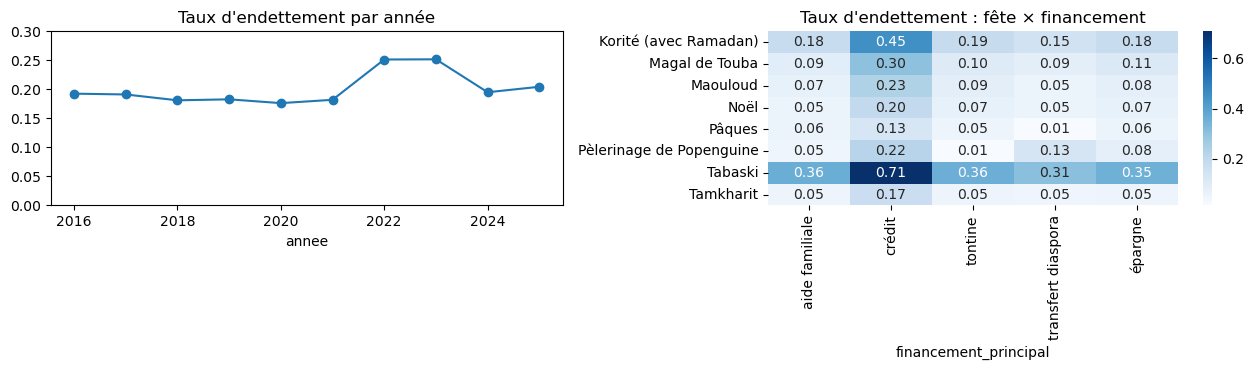

In [30]:
# Description : dépense médiane et taux d'endettement par fête et par mode de financement
par_fete_e = e.groupby("evenement").agg(menages=("menage_id", "size"), depense_mediane=("depense_totale_fcfa", "median"), taux_endettement=("endette_apres_fete", "mean")).sort_values("depense_mediane", ascending=False)
par_fin = e.groupby("financement_principal").agg(menages=("menage_id", "size"), depense_mediane=("depense_totale_fcfa", "median"), taux_endettement=("endette_apres_fete", "mean")).sort_values("taux_endettement", ascending=False)
croise = e.pivot_table(index="evenement", columns="financement_principal", values="endette_apres_fete", aggfunc="mean")
display(par_fete_e); display(par_fin)
fig, ax = plt.subplots(1, 2, figsize=(13, 3.8))
e.groupby("annee").endette_apres_fete.mean().plot(ax=ax[0], marker="o"); ax[0].set_title("Taux d'endettement par année"); ax[0].set_ylim(0, .3)
sns.heatmap(croise, annot=True, fmt=".2f", cmap="Blues", ax=ax[1]); ax[1].set_title("Taux d'endettement : fête × financement"); ax[1].set_ylabel("")
plt.tight_layout(); plt.show()

In [31]:
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import FunctionTransformer
from sklearn.metrics import roc_auc_score, average_precision_score, brier_score_loss
from sklearn.inspection import permutation_importance

ARGENT = ["revenu_mensuel_fcfa", "depense_totale_fcfa", "dep_alimentation_fcfa", "dep_habillement_fcfa", "dep_betail_fcfa", "dep_transport_ziara_fcfa", "dep_cadeaux_dons_fcfa"]
AUTRES = ["taille_menage", "ratio_dep_revenu", "membre_diaspora", "paiement_mobile"]
CATE = ["evenement", "region", "milieu", "financement_principal", "achat_mouton_cat", "religion", "confrerie"]
SENSIBLES = ["religion", "confrerie"]
TARGET = "endette_apres_fete"
tr, te = e[e.annee <= 2023], e[e.annee >= 2024]
print("Entraînement :", len(tr), "(taux", round(tr[TARGET].mean(), 3), ") | test :", len(te), "(taux", round(te[TARGET].mean(), 3), ")")

def pipe_logit(cate, argent=ARGENT, autres=AUTRES):
    pre = ColumnTransformer([
        ("argent", Pipeline([("imp", SimpleImputer(strategy="median")), ("log", FunctionTransformer(np.log1p)), ("sc", StandardScaler())]), argent),
        ("autres", Pipeline([("imp", SimpleImputer(strategy="median")), ("sc", StandardScaler())]), autres),
        ("cat", OneHotEncoder(handle_unknown="ignore"), cate)])
    return Pipeline([("prep", pre), ("clf", LogisticRegression(C=1.0, max_iter=2000, random_state=RANDOM_STATE))])

def pipe_hgb(cate, argent=ARGENT, autres=AUTRES):
    pre = ColumnTransformer([("cat", OrdinalEncoder(handle_unknown="use_encoded_value", unknown_value=-1), cate)], remainder="passthrough")
    h = HistGradientBoostingClassifier(max_iter=200, learning_rate=0.05, max_leaf_nodes=15, min_samples_leaf=50,
                                       categorical_features=list(range(len(cate))), random_state=RANDOM_STATE)
    return Pipeline([("prep", pre), ("clf", h)])

def evaluer(modele, cols, nom):
    modele.fit(tr[cols], tr[TARGET])
    p = modele.predict_proba(te[cols])[:, 1]
    return modele, p, {"modèle": nom, "ROC AUC": roc_auc_score(te[TARGET], p), "PR AUC": average_precision_score(te[TARGET], p), "Brier": brier_score_loss(te[TARGET], p)}

COLS_ALL = CATE + ARGENT + AUTRES
COLS_SANS = [c for c in COLS_ALL if c not in SENSIBLES]
m_logit, p_logit, r1 = evaluer(pipe_logit(CATE), COLS_ALL, "Régression logistique")
m_hgb, p_hgb, r2 = evaluer(pipe_hgb(CATE), [c for c in COLS_ALL if c in CATE] + ARGENT + AUTRES, "HistGradientBoosting")
brier_ref = brier_score_loss(te[TARGET], np.full(len(te), tr[TARGET].mean()))
ref = {"modèle": "Référence (taux moyen d'entraînement)", "ROC AUC": 0.5, "PR AUC": te[TARGET].mean(), "Brier": brier_ref}
comparaison = pd.DataFrame([ref, r1, r2]).set_index("modèle")
comparaison

Entraînement : 39462 (taux 0.201 ) | test : 9944 (taux 0.2 )


,ROC AUC,PR AUC,Brier
modèle,,,
Référence (taux moyen d'entraînement),0.500000,0.199718,0.159833
Régression logistique,0.823604,0.623370,0.113817
HistGradientBoosting,0.824562,0.624816,0.113502


Meilleur modèle : HistGradientBoosting


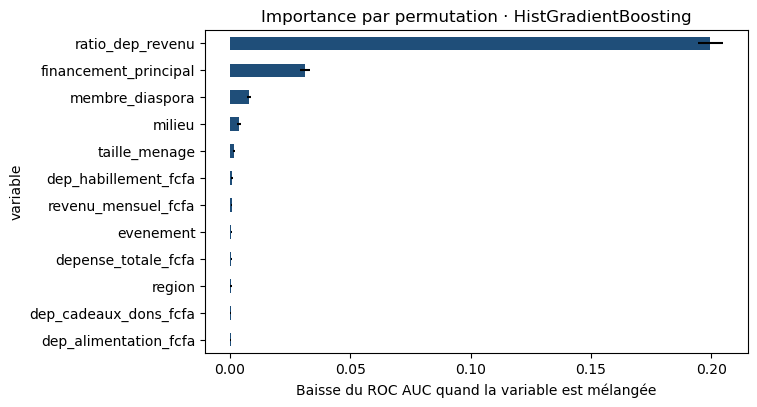

,variable,baisse d'AUC,écart-type
15,ratio_dep_revenu,0.199536,0.005314
3,financement_principal,0.031254,0.002138
16,membre_diaspora,0.007955,0.000769
2,milieu,0.003663,0.000801
14,taille_menage,0.001527,0.000399
10,dep_habillement_fcfa,0.000750,0.000374
7,revenu_mensuel_fcfa,0.000686,0.000281
0,evenement,0.000565,0.000187
8,depense_totale_fcfa,0.000491,0.000243
1,region,0.000475,0.000314


In [32]:
# Importance par permutation (sur le test, modèle complet, chaque colonne d'origine permutée séparément)
meilleur = m_hgb if r2["ROC AUC"] >= r1["ROC AUC"] else m_logit
nom_meilleur = "HistGradientBoosting" if meilleur is m_hgb else "Régression logistique"
cols_m = COLS_ALL
imp = permutation_importance(meilleur, te[cols_m], te[TARGET], scoring="roc_auc", n_repeats=5, random_state=RANDOM_STATE, n_jobs=1)
imp_df = pd.DataFrame({"variable": cols_m, "baisse d'AUC": imp.importances_mean, "écart-type": imp.importances_std}).sort_values("baisse d'AUC", ascending=False)
print("Meilleur modèle :", nom_meilleur)
fig, ax = plt.subplots(figsize=(7, 4.2))
imp_df.head(12).iloc[::-1].plot.barh(x="variable", y="baisse d'AUC", xerr="écart-type", ax=ax, legend=False, color="#1f4e79")
ax.set_title(f"Importance par permutation · {nom_meilleur}"); ax.set_xlabel("Baisse du ROC AUC quand la variable est mélangée"); plt.show()
imp_df.head(10)

In [33]:
# Question d'équité : on réentraîne le meilleur modèle SANS religion ni confrérie
if meilleur is m_hgb:
    m_sans, p_sans, r3 = evaluer(pipe_hgb([c for c in CATE if c not in SENSIBLES]), [c for c in CATE if c not in SENSIBLES] + ARGENT + AUTRES, nom_meilleur + " sans religion/confrérie")
else:
    m_sans, p_sans, r3 = evaluer(pipe_logit([c for c in CATE if c not in SENSIBLES]), COLS_SANS, nom_meilleur + " sans religion/confrérie")
equite = pd.DataFrame([r1 if meilleur is m_logit else r2, r3]).set_index("modèle")
equite.loc["écart"] = equite.iloc[1] - equite.iloc[0]
display(equite)

# Le signal « religion » passe-t-il par d'autres variables ? Taux d'endettement selon la fête et la religion, et prévisions moyennes par groupe
tab_rel = te.assign(p_avec=(p_hgb if meilleur is m_hgb else p_logit), p_sans=p_sans).groupby("religion").agg(
    menages=("menage_id", "size"), taux_reel=(TARGET, "mean"), proba_avec=("p_avec", "mean"), proba_sans=("p_sans", "mean"))
display(tab_rel)
e.pivot_table(index="evenement", columns="religion", values=TARGET, aggfunc=["mean", "size"])

,ROC AUC,PR AUC,Brier
modèle,,,
HistGradientBoosting,0.824562,0.624816,0.113502
HistGradientBoosting sans religion/confrérie,0.824419,0.625303,0.113452
écart,-0.000143,0.000487,-0.000050


,menages,taux_reel,proba_avec,proba_sans
religion,,,,
chrétien,421,0.109264,0.096915,0.096664
musulman,9523,0.203717,0.218060,0.217929


mean               size         
religion                  chrétien  musulman chrétien musulman
evenement                                                     
Korité (avec Ramadan)     0.072650  0.225704    234.0  11298.0
Magal de Touba                 NaN  0.127428      NaN   3861.0
Maouloud                       NaN  0.094611      NaN   4862.0
Noël                      0.143875  0.066038    702.0   2862.0
Pâques                    0.082621  0.052353    702.0   1700.0
Pèlerinage de Popenguine  0.083624       NaN    287.0      NaN
Tabaski                   0.072848  0.459462    302.0  11298.0
Tamkharit                      NaN  0.064436      NaN  11298.0

### Conclusion de la partie 5
**Description.** La Tabaski concentre l'endettement (**44,9 %** des ménages, dépense médiane 246 000 FCFA), loin devant la Korité (22,3 %) et les autres fêtes (6 à 13 %). Le crédit est de loin le financement le plus risqué (45,8 % d'endettés contre 13 à 16 % pour les autres). Le taux monte en 2022-2023 (25 %) avant de revenir à 20 %.

**Modèles.** Régression logistique et HGB sont à égalité : ROC AUC 0,824 contre 0,825, PR AUC 0,623 contre 0,625, Brier 0,114 pour les deux (0,160 pour la simple moyenne). Un modèle linéaire suffit ici, et il s'explique plus facilement. **Importance par permutation** : le rapport dépense/revenu domine (−0,20 d'AUC quand on le mélange), suivi du mode de financement (−0,031), de la présence d'un membre de la diaspora (−0,008) et du milieu (−0,004). Les variables de dépense brutes paraissent peu importantes parce qu'elles sont corrélées au ratio : la permutation sous-estime les variables redondantes.

### Question d'équité
Retirer la religion et la confrérie ne change rien : ROC AUC 0,825 → 0,824, PR AUC identique (0,625), Brier 0,114 → 0,113, et les probabilités moyennes prédites par groupe sont les mêmes (chrétiens 9,7 %, musulmans 21,8 %). Le signal passe déjà par les fêtes célébrées, le ratio dépense/revenu et le financement ; ces variables sensibles ne sont donc pas nécessaires. Pour un organisme de microfinance, les utiliser serait un risque sans gain : discrimination directe sur une caractéristique protégée. Mais les supprimer ne suffit pas : le modèle reste un proxy (la Tabaski explique l'écart brut de 10,9 % contre 20,4 %), donc il faut contrôler les erreurs par groupe. À noter, sur Noël seul, les chrétiens s'endettent plus (14,4 % contre 6,6 %), un écart que l'AUC globale ne voit pas parce que ces lignes sont rares : on vérifierait l'AUC par sous-groupe avant tout usage. Enfin ce modèle prédit une dette après une dépense festive, pas une capacité de remboursement ; il ne devrait pas servir seul à refuser un prêt (et les données sont simulées).

## Partie 6 · Profils de dépense (2025)

Pour chaque ménage de 2025 : dépenses sommées sur toutes ses fêtes, part de chacun des cinq postes, et **effort** = log(dépense annuelle des fêtes ÷ revenu mensuel). Standardisation puis K-means.

In [34]:
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

POSTES = ["dep_alimentation_fcfa", "dep_habillement_fcfa", "dep_betail_fcfa", "dep_transport_ziara_fcfa", "dep_cadeaux_dons_fcfa"]
e25 = e[e.annee == 2025]
# revenu manquant : médiane de la région × milieu (imputation faite avant l'agrégation, sur 2025 seulement)
e25 = e25.assign(revenu_mensuel_fcfa=e25.groupby(["region", "milieu"]).revenu_mensuel_fcfa.transform(lambda s: s.fillna(s.median())).fillna(e25.revenu_mensuel_fcfa.median()))
agg = e25.groupby("menage_id").agg(**{p: (p, "sum") for p in POSTES}, depense_annuelle=("depense_totale_fcfa", "sum"),
                                  revenu=("revenu_mensuel_fcfa", "first"), nb_fetes=("evenement", "size"), taille=("taille_menage", "first"),
                                  milieu=("milieu", "first"), endette=(TARGET, "max"))
parts = agg[POSTES].div(agg[POSTES].sum(axis=1), axis=0)
parts.columns = ["part_" + c.replace("dep_", "").replace("_fcfa", "") for c in POSTES]
agg["effort"] = np.log(agg.depense_annuelle / agg.revenu)
X6 = pd.concat([parts, agg[["effort"]]], axis=1)
print(X6.shape, "ménages en 2025")
Z = StandardScaler().fit_transform(X6)
sil = {}
for k in range(2, 9):
    km = KMeans(n_clusters=k, n_init=10, random_state=RANDOM_STATE).fit(Z)
    sil[k] = silhouette_score(Z, km.labels_)
sil = pd.Series(sil, name="silhouette"); sil

(1200, 6) ménages en 2025


2    0.477964
3    0.460452
4    0.264918
5    0.240174
6    0.246936
7    0.226012
8    0.201905
Name: silhouette, dtype: float64

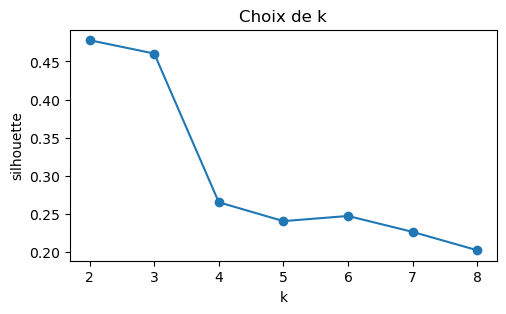

,menages,depense_mediane,revenu_median,effort_median,part_rurale,taux_endette,part_alimentation,part_habillement,part_betail,part_transport_ziara,part_cadeaux_dons
groupe,,,,,,,,,,,
0,954,610500.0,197000.0,1.149,0.452,0.643,0.304,0.259,0.263,0.071,0.103
1,64,199000.0,212000.0,0.005,0.359,0.312,0.475,0.219,0.002,0.064,0.241
2,182,404750.0,120500.0,1.174,0.632,0.637,0.396,0.369,0.009,0.091,0.135


In [35]:
fig, ax = plt.subplots(figsize=(5.5, 3)); sil.plot(marker="o", ax=ax); ax.set_xlabel("k"); ax.set_ylabel("silhouette"); ax.set_title("Choix de k"); plt.show()
K = 3   # silhouette quasi maximale (0,46 contre 0,48 pour k=2) et groupes interprétables ; à k=4 elle s'effondre (0,27) : on coupe un groupe en deux sans raison métier
km = KMeans(n_clusters=K, n_init=10, random_state=RANDOM_STATE).fit(Z)
agg["groupe"] = km.labels_
profil = agg.groupby("groupe").agg(menages=("depense_annuelle", "size"), depense_mediane=("depense_annuelle", "median"), revenu_median=("revenu", "median"),
                                   effort_median=("effort", "median"), part_rurale=("milieu", lambda s: (s == "rural").mean()), taux_endette=("endette", "mean"))
profil = profil.join(parts.groupby(agg.groupe).mean())
profil.round(3)

### Conclusion de la partie 6
**Choix de k.** Silhouette : 0,48 (k=2), **0,46 (k=3)**, 0,27 (k=4), puis 0,20 à 0,25. On garde **k=3** : sa silhouette est presque au maximum, il distingue un groupe de plus que k=2, et à k=4 la silhouette s'effondre, car on coupe en deux le groupe des acheteurs de mouton sans raison métier.

**Les trois groupes** (l'effort vaut environ log du nombre de mois de revenu dépensés ; exp(1,15) ≈ 3,2 mois) :
- **Acheteurs de mouton (954 ménages, 80 %)** : dépense annuelle médiane 610 500 FCFA, effort 1,15 (plus de trois mois de revenu), 26 % du budget en bétail ; 64 % s'endettent au moins une fois.
- **Ruraux modestes sans mouton (182 ménages, 15 %)** : revenu bas (120 500 FCFA), 63 % de ruraux, dépense 404 750 FCFA concentrée sur l'alimentation (40 %) et l'habillement (37 %), effort élevé (1,17), 64 % d'endettés. Ce sont les plus fragiles.
- **Petit effort, plus de cadeaux (64 ménages, 5 %)** : dépense d'environ un mois de revenu (effort ≈ 0), seulement 2,9 fêtes par an, 24 % de cadeaux et dons, 31 % d'endettés.

## Partie 7 · Plan 2026 et note de synthèse

Grille 2026 = 365 jours × 10 points de vente × 15 catégories (54 750 lignes), prévue avec le meilleur modèle réentraîné sur 2016-2025. Hypothèse sur les promotions : aucune promotion planifiée connue pour 2026, donc `promo = 0`.

In [36]:
train_final = df[~df.imputee]
cols_f = CAT_COLS + JEUX[JEU_FINAL]
modele_final = pipeline_hgb(CONFIG[0], CONFIG[1]).fit(train_final[cols_f], train_final.y)

dates26 = pd.date_range("2026-01-01", "2026-12-31")
grille = pd.MultiIndex.from_product([dates26, magasins.magasin_id, CATS], names=["date", "magasin_id", "categorie"]).to_frame(index=False)
grille = grille.merge(variables_calendrier(dates26), on="date", how="left")
grille["dow"] = grille.date.dt.dayofweek; grille["mois"] = grille.date.dt.month; grille["jour_annee"] = grille.date.dt.dayofyear
grille["annee"] = 2026; grille["promo"] = 0
grille["prevu"] = np.clip(modele_final.predict(grille[cols_f]), 0, None)
print(grille.shape, "| total prévu 2026 :", round(grille.prevu.sum()), "| réel 2025 :", round(df[df.annee == 2025].y.sum()))
grille.groupby("categorie").prevu.sum().div(df[df.annee == 2025].groupby("categorie").y.sum()).sub(1).mul(100).round(1).rename("variation 2026 vs 2025 (%)")

(54750, 26) | total prévu 2026 : 6899797 | réel 2025 : 6998877


categorie
arachide_bouye       -1.4
beaute_coiffure      -1.7
betail_mouton        -2.3
boissons             -1.3
cereales_mil         -1.7
credit_mobile        -1.7
dattes               -2.0
huile                -1.3
jouets_cadeaux       -1.7
lait                 -0.8
oignons              -1.6
riz                  -1.4
sucre                -1.1
tissus_habillement   -2.0
volaille             -1.8
Name: variation 2026 vs 2025 (%), dtype: float64

In [37]:
# Bonus : intervalles par régression quantile (HGB, perte « quantile »). On vérifie la couverture sur 2024 (modèle entraîné jusqu'en 2023), puis on réentraîne pour 2026.
def pipe_quantile(q):
    pre = ColumnTransformer([("cat", OrdinalEncoder(handle_unknown="use_encoded_value", unknown_value=-1), CAT_COLS)], remainder="passthrough")
    return Pipeline([("prep", pre), ("hgb", HistGradientBoostingRegressor(loss="quantile", quantile=q, categorical_features=[0, 1], max_iter=300,
                                                                          learning_rate=0.1, max_leaf_nodes=63, min_samples_leaf=40, random_state=RANDOM_STATE))])
for q in [0.1, 0.9]:
    mq = pipe_quantile(q).fit(train_val[cols_f], train_val.y)
    val["q%d" % int(q * 100)] = np.clip(mq.predict(val[cols_f]), 0, None)
cov = lambda s: float(((s.y >= s.q10) & (s.y <= s.q90)).mean())
print("Couverture de l'intervalle [q10 ; q90] en 2024 : année", round(cov(val), 3), "| fenêtres d'événement", round(cov(val[val.fenetre_14]), 3), "(cible 0,80)")
print("Part des ventes 2024 sous le q90 :", round(float((val.y <= val.q90).mean()), 3), "| en fenêtres :", round(float((val.y[val.fenetre_14] <= val.q90[val.fenetre_14]).mean()), 3))
q90_final = pipe_quantile(0.9).fit(train_final[cols_f], train_final.y)
grille["q90"] = np.maximum(np.clip(q90_final.predict(grille[cols_f]), 0, None), grille.prevu)   # un quantile 90 % ne peut pas être inférieur à la prévision centrale

Couverture de l'intervalle [q10 ; q90] en 2024 : année 0.75 | fenêtres d'événement 0.76 (cible 0,80)
Part des ventes 2024 sous le q90 : 0.878 | en fenêtres : 0.883


In [38]:
# Comparaison au réel 2025 : semaine avant la Tabaski, Magal à Touba, Noël
def somme(d, col, fete, annee, win, cats, mag=None):
    d0 = cal[(cal.evenement == fete) & (cal.annee == annee)].date_debut.iloc[0]
    s = d[d.date.between(d0 + J(win[0]), d0 + J(win[1])) & d.categorie.isin(cats)]
    if mag: s = s[s.magasin_id == mag]
    return s.groupby("categorie")[col].sum()

PLAN = [("Tabaski : semaine J-7 à J-1 (tous magasins)", "Tabaski", (-7, -1), None), ("Magal de Touba : J-5 à J-1 (Touba M05)", "Magal de Touba", (-5, -1), "M05"), ("Noël : semaine J-7 à J-1 (tous magasins)", "Noël", (-7, -1), None)]
unites = categories.set_index("categorie").unite
lignes = []
for titre, fete, win, mag in PLAN:
    cats = U.loc[fete].nlargest(3).index.tolist()
    reel25 = somme(test, "y", fete, 2025, win, cats, mag)            # réel 2025 (hors lignes imputées)
    prev25 = somme(test, "hgb", fete, 2025, win, cats, mag)          # ce que le modèle avait prévu pour 2025 un an à l'avance
    prev26 = somme(grille, "prevu", fete, 2026, win, cats, mag)
    q90 = somme(grille, "q90", fete, 2026, win, cats, mag)
    d0 = cal[(cal.evenement == fete) & (cal.annee == 2026)].date_debut.iloc[0]
    for c in cats:
        facteur = reel25[c] / prev25[c]                              # correction du biais de sous-estimation observé en 2025
        lignes.append({"pic": titre, "J0 2026": d0.date(), "catégorie": c, "unité": unites[c], "réel 2025": reel25[c], "prévu 2026 (brut)": prev26[c],
                       "facteur 2025": facteur, "recommandé 2026": prev26[c] * facteur, "variation (%)": 100 * (prev26[c] * facteur / reel25[c] - 1),
                       "plafond P90": max(q90[c] * facteur, prev26[c] * facteur)})
plan = pd.DataFrame(lignes)
plan.to_csv("C:/Users/admin/Downloads/plan_2026_pics.csv", index=False)
plan

,pic,J0 2026,catégorie,unité,réel 2025,prévu 2026 (brut),facteur 2025,recommandé 2026,variation (%),plafond P90
0,Tabaski : semaine J-7 à J-1 (tous magasins),2026-05-28,betail_mouton,tête,184.0,138.126958,1.298009,179.290101,-2.559728,407.349811
1,Tabaski : semaine J-7 à J-1 (tous magasins),2026-05-28,oignons,kg,37237.0,35510.827651,1.047230,37187.991108,-0.131613,46267.657131
2,Tabaski : semaine J-7 à J-1 (tous magasins),2026-05-28,tissus_habillement,article,4167.0,3743.689222,1.138887,4263.637838,2.319123,5700.383492
3,Magal de Touba : J-5 à J-1 (Touba M05),2026-08-02,credit_mobile,recharge,4281.0,4112.255871,0.981599,4036.587975,-5.709227,5063.220584
4,Magal de Touba : J-5 à J-1 (Touba M05),2026-08-02,boissons,bouteille,4414.0,4180.448861,0.959671,4011.857584,-9.110612,4933.602508
5,Magal de Touba : J-5 à J-1 (Touba M05),2026-08-02,riz,kg,11141.0,10576.994193,1.118099,11826.125615,6.149588,12130.418997
6,Noël : semaine J-7 à J-1 (tous magasins),2026-12-25,jouets_cadeaux,article,2538.0,2340.659642,1.081233,2530.798896,-0.283731,3330.029646
7,Noël : semaine J-7 à J-1 (tous magasins),2026-12-25,volaille,unité,4260.0,4297.411934,1.030415,4428.119491,3.946467,5625.078153
8,Noël : semaine J-7 à J-1 (tous magasins),2026-12-25,boissons,bouteille,23790.0,22355.346648,1.026243,22942.017190,-3.564451,28570.774339


In [39]:
from pathlib import Path

OUT_DIR = Path("outputs")
OUT_DIR.mkdir(parents=True, exist_ok=True)

In [40]:
# Plan quotidien complet 2026 (grille) sauvegardé pour la direction
grille[["date", "magasin_id", "categorie", "prevu", "q90"]].round(1).to_csv(OUT_DIR / "prevision_2026.csv", index=False)
print("Fichiers écrits :", sorted(p.name for p in OUT_DIR.iterdir()))

Fichiers écrits : ['prevision_2026.csv']


In [41]:
# Bonus : effet propre des promotions et biais de confusion
d_ok = df[~df.imputee].copy()
d_ok["y_rel"] = d_ok.y / d_ok.groupby(["magasin_id", "categorie", "annee"]).y.transform("mean")      # vente rapportée à la moyenne annuelle du couple
print("Taux de promotion hors fenêtres :", round(d_ok[~d_ok.fenetre_14].promo.mean() * 100, 2), "% | dans les fenêtres J-14..J-1 :", round(d_ok[d_ok.fenetre_14].promo.mean() * 100, 2), "%")
naif = d_ok[d_ok.promo == 1].y_rel.mean() / d_ok[d_ok.promo == 0].y_rel.mean()
hors = d_ok[~d_ok.fenetre_14]; dans = d_ok[d_ok.fenetre_14]
rel = lambda s: s[s.promo == 1].y_rel.mean() / s[s.promo == 0].y_rel.mean()
print("Rapport naïf des ventes promo / hors promo :", round(naif, 3), "| hors fenêtres :", round(rel(hors), 3), "| dans les fenêtres :", round(rel(dans), 3))
# Contrefactuel avec le modèle contrôlé par le calendrier : prévoir les mêmes lignes avec promo=1 puis promo=0
echant = d_ok[d_ok.annee >= 2024].sample(60000, random_state=RANDOM_STATE)
m_c = pipeline_hgb(CONFIG[0], CONFIG[1]).fit(d_ok[d_ok.annee <= 2023][cols_f], d_ok[d_ok.annee <= 2023].y)
p1 = m_c.predict(echant[cols_f].assign(promo=1)).sum(); p0 = m_c.predict(echant[cols_f].assign(promo=0)).sum()
print("Effet propre estimé par le modèle (ventes avec promo ÷ sans promo, toutes choses égales) :", round(p1 / p0, 3))

Taux de promotion hors fenêtres : 3.69 % | dans les fenêtres J-14..J-1 : 5.67 %
Rapport naïf des ventes promo / hors promo : 1.362 | hors fenêtres : 1.312 | dans les fenêtres : 1.372
Effet propre estimé par le modèle (ventes avec promo ÷ sans promo, toutes choses égales) : 1.279


### Conclusion de la partie 7
La grille 2026 compte 54 750 lignes (365 × 10 × 15). Le total prévu (6,90 M d'unités) est inférieur de 1,4 % au réel 2025 alors que les ventes croissent d'environ +1,6 % par an : `annee` n'est pas extrapolé par les arbres, donc la tendance n'est pas prolongée.

Comparaison avec le réel 2025 sur les trois pics (quantités **recommandées** = prévision 2026 × facteur réel/prévu observé en 2025, qui corrige la sous-estimation des pics) :
- **Tabaski 2026 (28 mai), semaine J-7 à J-1** : environ 179 moutons (184 en 2025), 37 200 kg d'oignons, 4 260 articles d'habillement. Plafond P90 des moutons : environ 390 têtes.
- **Magal à Touba 2026 (2 août), J-5 à J-1** : environ 11 800 kg de riz (+6 %), 4 040 recharges, 4 010 bouteilles.
- **Noël 2026, J-7 à J-1** : environ 2 530 jouets (−0,3 %), 4 430 volailles (+4 %), 22 900 bouteilles.

**Limites.** Un facteur de correction estimé sur la seule année 2025 est bruité (1,30 pour les moutons) ; la date réelle d'une fête musulmane peut bouger d'un jour ; on suppose aucune promotion et des prix inchangés ; le plafond P90 est la somme de quantiles quotidiens, donc supérieur au vrai quantile du total. L'intervalle [q10 ; q90] de la régression quantile ne couvre que 75 % des ventes 2024 (cible 80 %), il est un peu trop étroit.

**Bonus (promotions).** Les promotions sont plus fréquentes juste avant les fêtes (5,7 % des lignes dans les fenêtres contre 3,7 % ailleurs), et ces jours-là les ventes sont déjà élevées : comparer les ventes avec et sans promotion attribue à la promotion une partie de l'effet de la fête (biais de confusion). Rapport naïf des ventes promo/hors promo : 1,36 ; hors fenêtres de fête : 1,31 ; effet « toutes choses égales » estimé par le modèle : **1,28**. La promotion augmente donc les ventes d'environ 28 %, et le calcul naïf surestime d'environ 8 points. Le tableau de bord Streamlit n'a pas été réalisé.